# Step 7: Sentence-level to job-level labelling by average embedding (Technique 2)

**Method under test** (Dikshit et al., 2024, T2): average the sentence embeddings of each job ad, then run k-means (k = 3) and read the clusters as agentic / balanced / communal.

**This notebook tests the method, it does not assume it works.** Questions, each answered with a measurement:

| # | Question | Test |
|---|---|---|
| Q1 | Do sentence embeddings separate agentic from communal wording at all? (prerequisite) | Sentences with masculine- vs feminine-coded Gaucher words: centroid distance and an employer-grouped probe |
| Q2 | What do the k = 3 clusters of mean embeddings actually capture? | Cluster profile: length, job family, requirement-type mix |
| Q3 | Are the clusters stable? | Re-seeding, bootstrap, k from 2 to 8 |
| Q4 | Do the clusters agree with the Step 6 labels? | ARI, NMI, cross-tab |
| Q5 | Does averaging wash out a single biased sentence? | Inject "Male only" into ads and measure the change |
| Q6 | Is there a better job-level aggregation? | Max-pool of a sentence score vs mean-pool |

**Inputs and why**
- `step4_sentence_embeddings.npy` + `step4_sentence_units.csv` (Step 4): the sentence embeddings the method requires, built from the cased Step 2 masked text. Model `paraphrase-multilingual-MiniLM-L12-v2`.
- `step6_ad_level_analysis.csv` and `step6_sentence_level.csv` (Step 6): the dictionary labels used as an **imperfect reference**, not as ground truth.

In [1]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
OUT = "outputs/equal_step7_job_level_embedding"; os.makedirs(OUT, exist_ok=True)
SEED = 42

units = pd.read_csv("outputs/equal_step4_sentence_embeddings/step4_sentence_units.csv")
E = np.load("outputs/equal_step4_sentence_embeddings/step4_sentence_embeddings.npy")
ads = pd.read_csv("outputs/equal_step6_bias_analysis/step6_ad_level_analysis.csv").set_index("record_id")
s6 = pd.read_csv("outputs/equal_step6_bias_analysis/step6_sentence_level.csv")
assert len(units) == len(E), "embedding rows must align with unit rows"
print("sentence units:", len(units), "| embedding dim:", E.shape[1], "| ads:", units.record_id.nunique(), "| L2 norm mean:", np.linalg.norm(E, axis=1).mean().round(3))

sentence units: 7971 | embedding dim: 384 | ads: 1500 | L2 norm mean: 1.0


## 0. Align Step 4 units with Step 6 sentence flags
Step 6 re-segmented the same text; we check the two segmentations are identical before borrowing its sentence-level flags.

In [2]:
m = units.merge(s6, on=["sentence_id", "record_id"], how="left", suffixes=("", "_s6"), validate="one_to_one")
assert len(m) == len(units) == len(s6) and m.sentence_s6.notna().all(), "Step 4 and Step 6 units differ"
same = (m.sentence.str.strip() == m.sentence_s6.str.strip()).mean()
print(f"units aligned by sentence_id: {same:.4f} identical text")
if same < 0.999:
    print(m.loc[m.sentence.str.strip() != m.sentence_s6.str.strip(), ["record_id", "sentence", "sentence_s6"]].head())
units["masc_hits"] = m.masc_hits.values; units["fem_hits"] = m.fem_hits.values
units["explicit_unit_type"] = m.explicit_unit_type.fillna("").values

units aligned by sentence_id: 1.0000 identical text


## Q1. Do sentence embeddings separate agentic from communal wording?
If a sentence with masculine-coded words and one with feminine-coded words are not separable, averaging cannot recover the distinction at job level.

Reference sets are sentences whose coded words are **only masculine** or **only feminine**. Qualification-component sentences only, so job titles do not leak in.

In [3]:
q = units.component.eq("qualification")
masc_only = q & (units.masc_hits > 0) & (units.fem_hits == 0)
fem_only = q & (units.fem_hits > 0) & (units.masc_hits == 0)
neutral = q & (units.masc_hits + units.fem_hits == 0)
print("masculine-only sentences:", int(masc_only.sum()), "| feminine-only:", int(fem_only.sum()), "| neutral:", int(neutral.sum()))
cm, cf = E[masc_only].mean(0), E[fem_only].mean(0)
cn = lambda v: v / np.linalg.norm(v)
print("cosine(masc centroid, fem centroid):", round(float(cn(cm) @ cn(cf)), 3))
print("cosine(masc centroid, neutral centroid):", round(float(cn(cm) @ cn(E[neutral].mean(0))), 3))
print("cosine(fem  centroid, neutral centroid):", round(float(cn(cf) @ cn(E[neutral].mean(0))), 3))

# Employer-grouped probe: masculine-only vs feminine-only, de-duplicated sentences
sel = units[masc_only | fem_only].copy()
sel["y"] = (sel.fem_hits > 0).astype(int)
sel = sel.drop_duplicates("sentence")
Xs, ys, gs = E[sel.index], sel.y.values, sel.employer_id.values
res = {}
for name, X in [("embedding", Xs)]:
    pred = cross_val_predict(LogisticRegression(max_iter=2000, class_weight="balanced"), X, ys, groups=gs, cv=GroupKFold(5))
    res[name] = f1_score(ys, pred, average="macro")
print(f"probe n={len(sel)} (masc {int((ys==0).sum())}, fem {int((ys==1).sum())}) | embedding macro-F1 = {res['embedding']:.3f}")

# Control: does the same probe work from the coded words themselves (leakage / lexical check)?
from sklearn.feature_extraction.text import TfidfVectorizer
Xt = TfidfVectorizer(ngram_range=(1, 1), min_df=2).fit_transform(sel.sentence)
pred = cross_val_predict(LogisticRegression(max_iter=2000, class_weight="balanced"), Xt, ys, groups=gs, cv=GroupKFold(5))
print(f"TF-IDF control macro-F1 = {f1_score(ys, pred, average='macro'):.3f}")
print("majority-class baseline macro-F1 =", round(f1_score(ys, np.full_like(ys, np.bincount(ys).argmax()), average="macro"), 3))

masculine-only sentences: 219 | feminine-only: 243 | neutral: 5862
cosine(masc centroid, fem centroid): 0.833
cosine(masc centroid, neutral centroid): 0.785
cosine(fem  centroid, neutral centroid): 0.777
probe n=325 (masc 164, fem 161) | embedding macro-F1 = 0.855
TF-IDF control macro-F1 = 0.917
majority-class baseline macro-F1 = 0.335


## Job-level representation: average of sentence embeddings
Mean over all sentence units of an ad, then L2-normalised. Variants tested: all units, qualification units only (drops the job title and gender-line sentences that dominate topic).

In [4]:
def pool(mask=None, how="mean"):
    sub = units if mask is None else units[mask]
    g = sub.groupby("record_id").indices
    out, ids = [], []
    for rid, idx in g.items():
        v = E[sub.index[idx]]
        v = v.mean(0) if how == "mean" else v.max(0)
        out.append(v / np.linalg.norm(v)); ids.append(rid)
    return pd.DataFrame(out, index=ids)

X_all = pool()
X_qual = pool(units.component.eq("qualification"))
X_all = X_all.loc[ads.index]; common = ads.index.intersection(X_qual.index); X_qual = X_qual.loc[common]
print("ads with embeddings: all-units", len(X_all), "| qualification-only", len(X_qual))
n_units = units.groupby("record_id").size().reindex(ads.index)
print("sentence units per ad: median", int(n_units.median()), "| min", int(n_units.min()), "| max", int(n_units.max()), "| ads with 1-2 units:", int((n_units <= 2).sum()))

ads with embeddings: all-units 1500 | qualification-only 1343
sentence units per ad: median 5 | min 1 | max 20 | ads with 1-2 units: 206


## Q2. What do the k = 3 clusters capture?

In [5]:
def run_k(X, k=3, seed=SEED):
    km = KMeans(k, n_init=20, random_state=seed).fit(X.values)
    return km.labels_, km

lab_all, km_all = run_k(X_all)
prof = ads.copy(); prof["cluster"] = lab_all
prof["n_units"] = n_units
prof["title"] = units[units.component == "job_title"].groupby("record_id").sentence.first().reindex(prof.index)
sil = silhouette_score(X_all.values, lab_all)
print("silhouette (k=3, cosine geometry via unit vectors):", round(sil, 3))
print("cluster sizes:", pd.Series(lab_all).value_counts().sort_index().to_dict())
display(prof.groupby("cluster").agg(ads=("n_words", "size"), median_words=("n_words", "median"), median_units=("n_units", "median"),
                                   pct_explicit_male=("explicit_direction", lambda s: round((s == "male_restricted").mean() * 100, 1)),
                                   pct_explicit_female=("explicit_direction", lambda s: round((s == "female_restricted").mean() * 100, 1)),
                                   pct_any_coded_word=("masc_hits", lambda s: round(((s + prof.loc[s.index, "fem_hits"]) > 0).mean() * 100, 1))))
for c in sorted(prof.cluster.unique()):
    print(f"\ncluster {c} example titles:", prof[prof.cluster == c].title.dropna().sample(8, random_state=1).tolist())
# component mix of units inside each cluster's ads
mix = units.assign(cluster=units.record_id.map(prof.cluster)).groupby(["cluster", "component"]).size().unstack(fill_value=0)
display((mix.div(mix.sum(1), axis=0) * 100).round(1))

silhouette (k=3, cosine geometry via unit vectors): 0.065
cluster sizes: {0: 374, 1: 747, 2: 379}


,ads,median_words,median_units,pct_explicit_male,pct_explicit_female,pct_any_coded_word
cluster,,,,,,
0,374,23.5,5.0,37.2,17.9,11.8
1,747,43.0,6.0,3.3,5.6,41.1
2,379,25.0,4.0,11.3,0.8,15.6



cluster 0 example titles: ['Teacher III', 'Truck Helper', 'Carpenter', 'Stock and Sales Clerks', 'Aircon Technician', 'Purchasing Staff', 'Inventroy Staff (Reserve)', 'Emergency Room Staff Nurse']

cluster 1 example titles: ['Cook', 'Sales Documentation and Turnover Staff', 'Social Welfare Officer III', 'Service Crew', 'Sales Assistant', 'Accounts Payable Specialist', 'Information Admitting Staff', 'Dining Supervisor']

cluster 2 example titles: ['Pump Attendant', 'Refrigeration Operator', 'Auto Electrician', 'Truck Driver', 'Forklift Operators', 'Fiber Splicer', 'Building Maintenance/Electrician', 'Water Truck Driver']


component,body_other,job_title,qualification
cluster,,,
0,1.2,20.2,78.6
1,1.2,16.0,82.7
2,1.5,25.5,73.0


## Q3. Stability

In [6]:
base = lab_all
seeds = [run_k(X_all, 3, s)[0] for s in range(10)]
print("re-seeding ARI vs base (10 seeds): min %.3f, mean %.3f" % (min(adjusted_rand_score(base, s) for s in seeds), np.mean([adjusted_rand_score(base, s) for s in seeds])))

rng = np.random.RandomState(SEED); boots = []
for b in range(30):
    idx = rng.choice(len(X_all), len(X_all), replace=True)
    km = KMeans(3, n_init=5, random_state=b).fit(X_all.values[idx])
    boots.append(adjusted_rand_score(base, km.predict(X_all.values)))
print("bootstrap ARI vs base (30 resamples): median %.3f, 5th pct %.3f" % (np.median(boots), np.percentile(boots, 5)))

rows = []
for k in range(2, 9):
    l, _ = run_k(X_all, k)
    rows.append((k, round(silhouette_score(X_all.values, l), 3)))
display(pd.DataFrame(rows, columns=["k", "silhouette"]).set_index("k").T)

re-seeding ARI vs base (10 seeds): min 0.971, mean 0.993
bootstrap ARI vs base (30 resamples): median 0.850, 5th pct 0.718


k,2,3,4,5,6,7,8
silhouette,0.083,0.065,0.05,0.055,0.06,0.054,0.059


## Q4. Agreement with the Step 6 labels
The Step 6 coded-word label is an imperfect reference (72% of ads have no coded word, and the labels depend on the lexicon). Low agreement is therefore evidence about the clusters **and** the reference; we report the cluster profile above to separate the two.

In [7]:
ref = ads.coded_label
mask = ref != "no_signal"
print("ads with any coded word (reference exists):", int(mask.sum()))
for name, r in [("all 1,500 ads (no_signal kept as a class)", ref), ("only ads with a coded word", ref[mask])]:
    idx = r.index; c = pd.Series(lab_all, index=ads.index).loc[idx]
    print(f"\n{name}: ARI {adjusted_rand_score(r, c):.3f} | NMI {normalized_mutual_info_score(r, c):.3f}")
    display(pd.crosstab(c.rename("cluster"), r))
exp = ads.explicit_direction
c_all = pd.Series(lab_all, index=ads.index)
print("Cluster vs explicit direction: NMI %.3f" % normalized_mutual_info_score(exp, c_all))
display(pd.crosstab(c_all.rename("cluster"), exp))
# what the clusters DO track: job family proxy = TF-IDF cluster from Step 4
tf = units.groupby("record_id").tfidf_cluster.agg(lambda s: s.value_counts().index[0]).reindex(ads.index)
print("Cluster vs dominant TF-IDF unit cluster (job-content proxy): NMI %.3f" % normalized_mutual_info_score(tf, c_all))

ads with any coded word (reference exists): 410

all 1,500 ads (no_signal kept as a class): ARI -0.045 | NMI 0.067


coded_label,agentic_masculine_coded,balanced,communal_feminine_coded,no_signal
cluster,,,,
0,4,1,39,330
1,133,48,126,440
2,27,4,28,320



only ads with a coded word: ARI -0.020 | NMI 0.059


coded_label,agentic_masculine_coded,balanced,communal_feminine_coded
cluster,,,
0,4,1,39
1,133,48,126
2,27,4,28


Cluster vs explicit direction: NMI 0.188


explicit_direction,female_restricted,inclusive_only,male_restricted,mixed_restrictions,none
cluster,,,,,
0,67,68,139,1,99
1,42,33,25,0,647
2,3,1,43,0,332


Cluster vs dominant TF-IDF unit cluster (job-content proxy): NMI 0.006


## Q5. Does averaging wash out a biased sentence?
We take ads with **no** explicit gender wording, append the single sentence *"Male only"* (or *"Female only"*), re-average, and ask: how far does the job vector move compared with the normal distance between different ads, and does the cluster change?

In [8]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
probes = {"Male only": None, "Female only": None, "Open to all genders": None}
for k in probes: probes[k] = model.encode([k], normalize_embeddings=True, show_progress_bar=False)[0]

clean = ads.index[(ads.explicit_direction == "none")]
g = units.groupby("record_id").indices
sums = {r: E[units.index[g[r]]].sum(0) for r in clean}
cnt = {r: len(g[r]) for r in clean}
base_vec = {r: sums[r] / cnt[r] for r in clean}
unit = lambda v: v / np.linalg.norm(v)
rng = np.random.RandomState(SEED)
samp = rng.choice(clean, 600, replace=False)
Xall_n = X_all.values; pos = {r: i for i, r in enumerate(ads.index)}
# typical distance between two different ads, and to the nearest other ad
rand_cos = np.array([unit(base_vec[a]) @ unit(base_vec[b]) for a, b in rng.choice(samp, (1500, 2))])
print("cosine between two random ads: median %.3f (5th-95th pct %.3f to %.3f)" % (np.median(rand_cos), *np.percentile(rand_cos, [5, 95])))
rows = []
for name, pv in probes.items():
    shift, flips = [], 0
    for r in samp:
        new = unit((sums[r] + pv) / (cnt[r] + 1))
        shift.append(float(unit(base_vec[r]) @ new))
        flips += int(km_all.predict(new.reshape(1, -1))[0] != lab_all[pos[r]])
    shift = np.array(shift)
    rows.append((name, round(np.median(shift), 3), round(np.percentile(shift, 5), 3), round(flips / len(samp) * 100, 1)))
display(pd.DataFrame(rows, columns=["injected sentence", "median cos(before, after)", "5th pct", "% ads changing cluster"]).set_index("injected sentence"))
n_short = pd.Series(cnt).reindex(samp)
print("median units in sampled ads:", int(n_short.median()))
# does the effect shrink as the ad gets longer?
dd = pd.DataFrame({"n": n_short.values, "cos": [float(unit(base_vec[r]) @ unit((sums[r] + probes['Male only']) / (cnt[r] + 1))) for r in samp]})
dd["bucket"] = pd.cut(dd.n, [0, 3, 6, 10, 100])
display(dd.groupby("bucket").cos.agg(["count", "median"]).round(3))
# Male-only vs Female-only vector difference relative to ad-to-ad spread
mf = float(probes["Male only"] @ probes["Female only"])
print("cosine(Male only, Female only) as sentences: %.3f" % mf)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3073.70it/s]


cosine between two random ads: median 0.507 (5th-95th pct 0.188 to 0.732)


,"median cos(before, after)",5th pct,% ads changing cluster
injected sentence,,,
Male only,0.956,0.739,38.2
Female only,0.957,0.734,36.2
Open to all genders,0.958,0.728,32.5


median units in sampled ads: 5


,count,median
bucket,,
"(0, 3]",179,0.874
"(3, 6]",265,0.958
"(6, 10]",138,0.980
"(10, 100]",18,0.990


cosine(Male only, Female only) as sentences: 0.791


## Q6. A better aggregation? Sentence score, then max or share, instead of the mean
Test only, using the Step 6 sentence flags as the (weak) sentence-level signal: score each sentence by projection on the masculine-minus-feminine centroid direction, then aggregate by max / min / mean and compare with the dictionary label on ads that have a coded word.

In [9]:
d_vec = cn(cm) - cn(cf)
units["proj"] = E @ d_vec
agg = units.groupby("record_id").proj.agg(mean="mean", max="max", min="min").reindex(ads.index)
sub = ads.index[ads.coded_label.isin(["agentic_masculine_coded", "communal_feminine_coded"])]
y = (ads.loc[sub, "coded_label"] == "agentic_masculine_coded").astype(int)
from sklearn.metrics import roc_auc_score
res = {k: roc_auc_score(y, agg.loc[sub, k]) for k in ["mean", "max", "min"]}
print("AUC of projection score vs dictionary agentic/communal label (ads with an agentic or communal label, n=%d):" % len(sub), {k: round(v, 3) for k, v in res.items()})
print("NOTE: sentences with coded words defined the direction, so this is optimistic (circular). It is shown only to compare aggregators.")
# non-circular version: define direction from half the employers, evaluate on the others
emps = ads.employer_id.unique(); rng = np.random.RandomState(SEED); rng.shuffle(emps)
tr_e = set(emps[: len(emps) // 2])
trm = masc_only & units.employer_id.isin(tr_e); trf = fem_only & units.employer_id.isin(tr_e)
d2 = cn(E[trm].mean(0)) - cn(E[trf].mean(0))
units["proj2"] = E @ d2
agg2 = units.groupby("record_id").proj2.agg(mean="mean", max="max", min="min").reindex(ads.index)
te = [r for r in sub if ads.loc[r, "employer_id"] not in tr_e]
y2 = (ads.loc[te, "coded_label"] == "agentic_masculine_coded").astype(int)
print("held-out employers (n=%d):" % len(te), {k: round(roc_auc_score(y2, agg2.loc[te, k]), 3) for k in ["mean", "max", "min"]})

AUC of projection score vs dictionary agentic/communal label (ads with an agentic or communal label, n=357): {'mean': 0.847, 'max': 0.766, 'min': 0.787}
NOTE: sentences with coded words defined the direction, so this is optimistic (circular). It is shown only to compare aggregators.
held-out employers (n=198): {'mean': 0.807, 'max': 0.763, 'min': 0.782}


## Save outputs

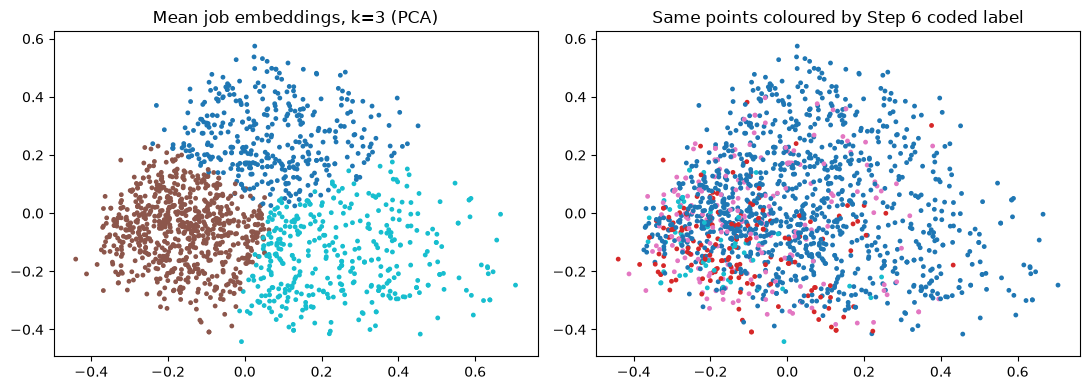

['step7_job_level_clusters_k3.csv', 'step7_job_mean_embeddings.csv.gz', 'step7_pca.png']


In [10]:
out = prof.reset_index()[["record_id", "employer_id", "cluster", "n_units", "n_words", "coded_label", "explicit_direction", "title"]]
out.to_csv(f"{OUT}/step7_job_level_clusters_k3.csv", index=False)
X_all.to_csv(f"{OUT}/step7_job_mean_embeddings.csv.gz")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
from sklearn.decomposition import PCA
P = PCA(2, random_state=SEED).fit_transform(X_all.values)
ax[0].scatter(P[:, 0], P[:, 1], c=lab_all, s=6, cmap="tab10"); ax[0].set_title("Mean job embeddings, k=3 (PCA)")
cl = ads.coded_label.map({"no_signal": 0, "agentic_masculine_coded": 1, "communal_feminine_coded": 2, "balanced": 3})
ax[1].scatter(P[:, 0], P[:, 1], c=cl, s=6, cmap="tab10"); ax[1].set_title("Same points coloured by Step 6 coded label")
plt.tight_layout(); plt.savefig(f"{OUT}/step7_pca.png", dpi=130); plt.show()
print(sorted(os.listdir(OUT)))

## Reading guide
- A positive Q1 is **necessary** for the method; a positive Q4 against a weak reference is not sufficient.
- Q2 shows what the clusters represent. If they follow job family or ad length, naming them agentic / balanced / communal would be arbitrary.
- Q5 measures whether one biased sentence survives averaging.
- Q6 is a test of alternatives, not an adoption decision.